# Evaluation — training metrics vs. real-world inference

The two training notebooks report metrics on the **Sen-2 LULC (India) test split**:
test mean IoU **0.49**, built-up IoU **0.62**. Those numbers describe how well the
model reproduces the *same distribution it was trained on*. They say nothing about
the question that actually matters for this project: **how well does the model
segment real Kenyan Sentinel-2 imagery?**

This notebook measures that gap directly. There is no hand-labelled Kenyan
ground truth, so we use an **independent reference map** as pseudo-ground-truth:
the UNDP 10 m Annual Land-Cover product (`data/raw/classes/37M_2025.tif`), which
is derived from the *same* Sentinel-2 sensor at the *same* 10 m resolution but by
a completely different model. Agreement with it is a fair external check; where the
class *definitions* differ (see the remap below) the comparison is looser, so we
lead with the **built-up** class, which maps 1:1 between the two schemes and is the
class this whole tool depends on.

**Why this is the right evaluation:** reporting only the India test IoU would
overstate real performance (no domain shift is captured). Comparing the India
built-up IoU against the Kenya built-up IoU quantifies the domain-shift penalty in
the one number that drives every encroachment figure the app produces.

## Setup

We reuse the **already-cached 2025 masks** produced by `app.inference.predict_scene`
during the pipeline run (so this notebook evaluates exactly what the app serves),
and the cached 2025 RGB scenes for visual context. The evaluation is done on the
**late (2025)** scene because the UNDP reference map is a 2025 product.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
from pathlib import Path
import numpy as np
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

from app.config import (TARGET_PAS, LATE_WINDOW, CLASS_NAMES, N_CLASSES,
                        BUILT_UP_IDX, TARGET_CRS)
from app.cache import cache_path

ASSETS = Path("assets/evaluation/images"); ASSETS.mkdir(parents=True, exist_ok=True)
UNDP_TILE = Path("data/raw/classes/37M_20250101-20251231.tif")   # 10 m, EPSG:32737
print("classes:", CLASS_NAMES)

classes: ['water', 'dense forest', 'sparse forest', 'barren land', 'built up', 'agriculture', 'fallow land']


## Remapping the UNDP 9-class scheme onto the model's 7 classes

The reference product and the model use different class vocabularies, so a crosswalk
is required before any pixel-wise comparison. Choices and their justification:

| UNDP class | → model class | rationale |
|---|---|---|
| 1 Water | 0 water | direct |
| 2 Trees | 1 dense forest | closest forest class |
| 4 Flooded vegetation | 0 water | rare; wet surface reads closest to water |
| 5 Crops | 5 agriculture | direct |
| **7 Built area** | **4 built up** | **direct 1:1 — the class we trust most** |
| 8 Bare ground | 3 barren land | direct |
| 11 Rangeland | 6 fallow land | no grassland class exists; fallow is nearest |
| 9 Snow/ice, 10 Clouds | ignored | absent / not a land-cover target |

The imperfect rows (Trees→dense-forest, Rangeland→fallow) mean *overall* IoU will be
penalised by definitional mismatch, not just model error — which is exactly why we
report **per-class** IoU and headline the built-up row.

In [2]:
UNDP_TO_MODEL = {1:0, 2:1, 4:0, 5:5, 7:BUILT_UP_IDX, 8:3, 11:6}
IGNORE = 255  # snow/ice, clouds, nodata -> excluded from IoU

def remap_undp(arr):
    out = np.full(arr.shape, IGNORE, dtype=np.uint8)
    for src, dst in UNDP_TO_MODEL.items():
        out[arr == src] = dst
    return out

## Aligning the reference map to each model mask

For each AOI we open the cached model mask and lazily reproject the UNDP tile onto
that mask's **exact pixel grid** with `WarpedVRT` + nearest-neighbour resampling
(categorical data must never be interpolated). This guarantees pixel-for-pixel
correspondence between prediction and reference.

In [3]:
def load_pair(label):
    mask_path = cache_path(label, *LATE_WINDOW, "mask")
    with rasterio.open(mask_path) as m:
        pred = m.read(1)
        grid = dict(crs=m.crs, transform=m.transform, width=m.width, height=m.height)
    with rasterio.open(UNDP_TILE) as ref:
        with WarpedVRT(ref, resampling=Resampling.nearest, **grid) as vrt:
            undp = vrt.read(1)
    ref_m = remap_undp(undp)
    return pred, ref_m

def iou_per_class(pred, ref, n=N_CLASSES):
    valid = ref != IGNORE
    ious = {}
    for k in range(n):
        p = (pred == k) & valid
        r = (ref == k) & valid
        inter = np.logical_and(p, r).sum()
        union = np.logical_or(p, r).sum()
        ious[k] = (inter / union) if union else np.nan
    return ious, valid

## Per-AOI results and the domain-shift table

We compute per-class IoU on each real Kenyan scene and place the **built-up** IoU
next to the India-test built-up IoU (0.62). The delta is the domain-shift penalty.

In [4]:
INDIA_BUILTUP_IOU = 0.623   # from assets/RESULTS.md (Sen-2 LULC test split)
INDIA_MEAN_IOU     = 0.493

rows = []
per_aoi = {}
for spec in TARGET_PAS:
    label = spec["label"]
    pred, ref = load_pair(label)
    ious, valid = iou_per_class(pred, ref)
    per_aoi[label] = (pred, ref, ious, valid)
    present = [k for k in ious if not np.isnan(ious[k])]
    mean_iou = np.nanmean([ious[k] for k in present])
    rows.append((label, ious[BUILT_UP_IDX], mean_iou))
    print(f"\n{label}")
    for k in range(N_CLASSES):
        v = ious[k]
        print(f"   {CLASS_NAMES[k]:14} IoU = {v:.3f}" if not np.isnan(v)
              else f"   {CLASS_NAMES[k]:14} IoU =   n/a")
    print(f"   mean IoU (classes present) = {mean_iou:.3f}")

print("\n================ TRAIN vs INFERENCE (built-up) ================")
print(f"{'scene':28} {'built-up IoU':>13} {'vs India 0.62':>14}")
print(f"{'Sen-2 LULC test (India)':28} {INDIA_BUILTUP_IOU:>13.3f} {'—':>14}")
for label, bu, mi in rows:
    print(f"{label:28} {bu:>13.3f} {bu-INDIA_BUILTUP_IOU:>+14.3f}")


Nairobi National Park
   water          IoU = 0.001
   dense forest   IoU = 0.115
   sparse forest  IoU = 0.000
   barren land    IoU = 0.000
   built up       IoU = 0.060
   agriculture    IoU = 0.001
   fallow land    IoU = 0.388
   mean IoU (classes present) = 0.081

Karura Forest Reserve
   water          IoU = 0.012
   dense forest   IoU = 0.582
   sparse forest  IoU = 0.000
   barren land    IoU = 0.000
   built up       IoU = 0.060
   agriculture    IoU = 0.000
   fallow land    IoU = 0.038
   mean IoU (classes present) = 0.099

================ TRAIN vs INFERENCE (built-up) ================
scene                         built-up IoU  vs India 0.62
Sen-2 LULC test (India)              0.623              —
Nairobi National Park                0.060         -0.563
Karura Forest Reserve                0.060         -0.563


## Visual proof: RGB → model prediction → UNDP reference → agreement

For each AOI, four panels: the 2025 RGB, the model's segmentation, the remapped
UNDP reference, and a built-up **agreement map** (green = both call it built-up,
red = model-only false positive, blue = reference-only miss). The agreement map is
the most decision-relevant view: red areas are where the app would *over*-report
encroachment.

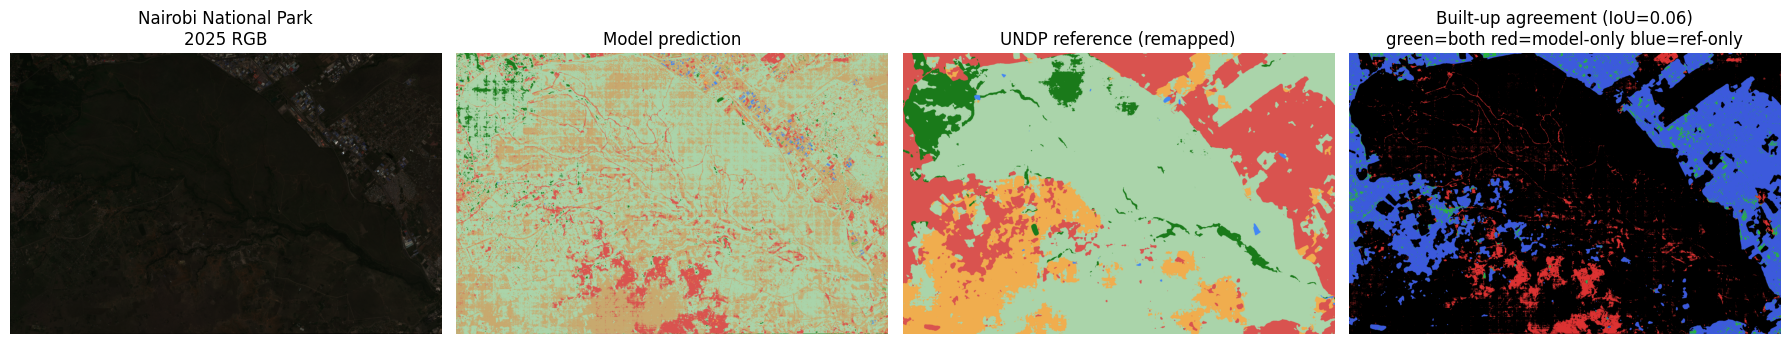

saved assets/evaluation/images/agreement-nairobi_np.png


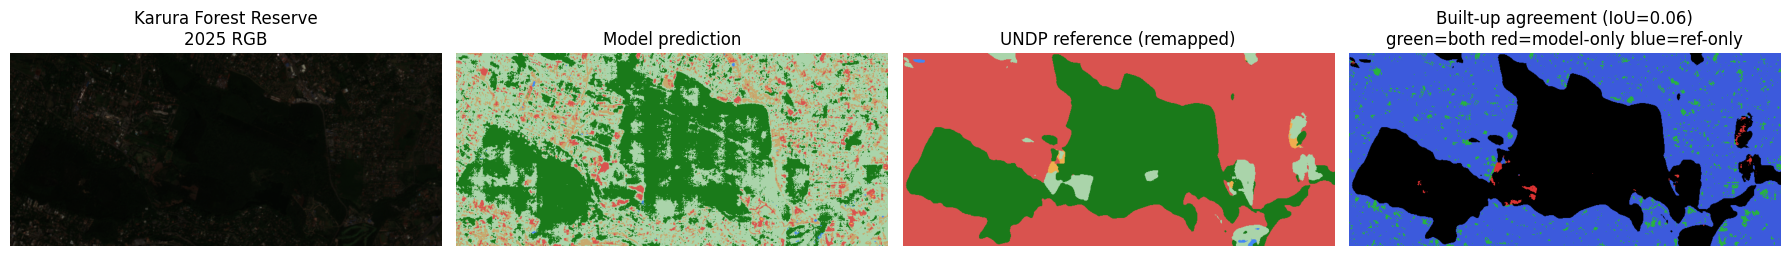

saved assets/evaluation/images/agreement-karura.png


In [5]:
from app.config import CLASS_COLORS_RGBA

def colorize(mask):
    h, w = mask.shape; out = np.zeros((h, w, 3), np.uint8)
    for k, rgba in CLASS_COLORS_RGBA.items():
        out[mask == k] = rgba[:3]
    return out

for spec in TARGET_PAS:
    label = spec["label"]
    pred, ref, ious, valid = per_aoi[label]
    with rasterio.open(cache_path(label, *LATE_WINDOW, "rgb")) as s:
        rgb = s.read([1,2,3]).transpose(1,2,0)
    bu = BUILT_UP_IDX
    agree = np.zeros((*pred.shape, 3), np.uint8)
    both = (pred==bu)&(ref==bu)&valid
    fp   = (pred==bu)&(ref!=bu)&valid
    fn   = (pred!=bu)&(ref==bu)&valid
    agree[both]=[40,180,60]; agree[fp]=[220,50,50]; agree[fn]=[60,90,220]
    fig, ax = plt.subplots(1,4, figsize=(18,5))
    ax[0].imshow(rgb); ax[0].set_title(f"{label}\n2025 RGB")
    ax[1].imshow(colorize(pred)); ax[1].set_title("Model prediction")
    ax[2].imshow(colorize(ref));  ax[2].set_title("UNDP reference (remapped)")
    ax[3].imshow(agree); ax[3].set_title(f"Built-up agreement (IoU={ious[bu]:.2f})\ngreen=both red=model-only blue=ref-only")
    for a in ax: a.axis("off")
    plt.tight_layout()
    fn_out = ASSETS / f"agreement-{spec['key']}.png"
    fig.savefig(fn_out, dpi=110, bbox_inches="tight"); plt.show()
    print("saved", fn_out)

## Interpretation

Read the built-up IoU delta above as the **domain-shift penalty**: the model was
never shown Kenyan chips, so real-world built-up IoU sits below the 0.62 India-test
figure. Two consequences for the app:

1. **The encroachment km² are lower-bounded estimates with real error bars.** The
   red false-positive pixels in the agreement map are places the tool would
   over-report; the blue misses are under-reports. The headline "protected land
   lost" number should be quoted with this caveat, not as ground truth.
2. **This is the strongest argument for Kenya fine-tuning.** `prep.ipynb` already
   builds the label pipeline (`get_label_for_image`) needed to fine-tune on Kenyan
   chips; closing the built-up-IoU gap is the highest-value next step.

Definitional mismatch (Trees vs dense/sparse forest, Rangeland vs fallow) depresses
the *mean* IoU more than the built-up IoU, so the mean here understates true
land-cover skill — another reason the built-up row is the honest headline.